# fresh-releases

Three new-release radars over the same artist, plus a credits-based
collaborator pipeline for Qobuz. This notebook showcases what each file does
and what its data looks like.

Seed artist throughout: **Jorge Drexler** (Qobuz `41620`, MusicBrainz
`abb91078-f7db-41f2-8f07-7f37bb739143`, Apple `16421943`).

Stdlib + matplotlib only, to match the scripts. No pandas.


## Setup


In [2]:
import json, subprocess, collections, sys
from pathlib import Path

HERE = Path.cwd() if (Path.cwd() / "data").is_dir() else Path.cwd().parent
DATA = HERE / "data"
def load(name):
    p = DATA / name
    return json.loads(p.read_text()) if p.exists() else None

# Set False to skip every network call and read only the stored artifacts.
RUN_LIVE = False   # flip on deliberately: the radars make live API calls

for f in sorted(HERE.glob('*/*.py')) + sorted(DATA.glob('*.json')):
    print(f'{f.name:<26} {f.stat().st_size:>9,} bytes')


fresh_releases.py              6,715 bytes
ingest-01-listens.py           4,991 bytes
itunes_releases.py             8,956 bytes
qobuz_discover.py             14,039 bytes
qobuz_keys.py                  1,154 bytes
qobuz_releases.py             11,374 bytes
qobuz_resolve.py              11,875 bytes
discovery_41620.json         257,208 bytes
itunes_seen.json                 945 bytes
pool.json                    966,402 bytes
qobuz_seen.json                1,073 bytes
watchlist.json               121,995 bytes


## 1. The radars

Same job, same output shape, three catalogues. Each keeps its own state file so
a second run reports only what is new. None of them needs an API key or login.

| script | source | artist id namespace |
|---|---|---|
| `fresh_releases.py` | ListenBrainz (MusicBrainz-derived) | MBID |
| `itunes_releases.py` | iTunes Search API | Apple artist id |
| `qobuz_releases.py` | Qobuz storefront | Qobuz artist id |

`--all` ignores the state file, so this shows everything each source knows
about within its window rather than only what is new since the last run.


In [3]:
def run(script, *args, timeout=180):
    if not RUN_LIVE:
        return '(RUN_LIVE is False)'
    try:
        r = subprocess.run([sys.executable, str(HERE / script), *args], cwd=HERE,
                           capture_output=True, text=True, timeout=timeout)
        return (r.stdout or '') + (r.stderr or '')
    except subprocess.TimeoutExpired:
        return f'(timed out after {timeout}s)'

for script in ['radars/listenbrainz.py', 'radars/itunes.py', 'radars/qobuz.py']:
    print(f'===== {script} =====')
    print(run(script, '--all').strip() or '(no output)')
    print()


===== fresh_releases.py =====
Scanned 3335 releases in a +/-14 day window around 2026-08-30, watching 1 artist.
Nothing new.

===== itunes_releases.py =====
Scanned 69 releases from 1 artist in the US store (last 90 days).

  2026-06-04  Single             No Te Va Gustar, Jorge Drexler, Agarrate Catalina & Hugo Fattoruso - Cielo De Un Solo Color (1 tr)
  2026-08-06  Single             Fernando Cabrera & Jorge Drexler - Méritos Y Merecimientos (1 tr)

2 new releases.

===== qobuz_releases.py =====
Scanned 63 releases from 1 artist in the gb-en store (last 90 days).

  2026-06-04  Single             No te va Gustar, Jorge Drexler, Agarrate Catalina, Hugo Fattoruso - Cielo De Un Solo Color (1 tr, hi-res)
  2026-08-06  Single             Fernando Cabrera, Jorge Drexler - Méritos Y Merecimientos (1 tr)

2 new releases.



### What that comparison shows

iTunes and Qobuz both report the 2026-08-06 single *Méritos Y Merecimientos*
(Fernando Cabrera & Jorge Drexler). ListenBrainz does not — MusicBrainz has no
record of it.

That is the coverage lesson: **MusicBrainz lags badly on singles and on
non-Anglophone artists.** It is the only one of the three that models credits,
which is exactly the tension the Qobuz pipeline below resolves — Qobuz turns out
to carry credits *and* be current.


## 2. Discovery — who made the seed's records

`qobuz_discover.py` walks every release by one artist, reads the per-track
`performers` string Qobuz ships on `album/get`, and reduces it to distinct
people with per-album evidence.

Exact and cacheable: it only parses what Qobuz already returned, so it makes no
guesses. Album credits are cached in `.credits_cache/`, so a re-run is instant.


In [4]:
d = load('discovery_41620.json')
assert d, 'run ./stages/discover.py first'
seed = d['seed']
print(f"seed          : {seed['name']} ({seed['qobuz_id']}), store {seed['store']}")
print(f"releases      : {seed['releases']}")
print(f"tracks        : {seed['credited_tracks']}/{seed['tracks']} carry credits")
print(f"people kept   : {len(d['people'])} (musical roles)")
print(f"dropped       : {d['dropped_non_musical']} (designers, studios, admin)")
print(f"on 2+ albums  : {sum(1 for p in d['people'] if p['stats']['albums'] >= 2)}")


seed          : Jorge Drexler (41620), store gb-en
releases      : 63
tracks        : 265/265 carry credits
people kept   : 278 (musical roles)
dropped       : 72 (designers, studios, admin)
on 2+ albums  : 122


**100% of tracks carry credits**, across every decade from the 1990s to 2026.
There is no backfill delay: the single released three weeks before this was
written already lists its two producers.

Ranking uses **albums, not tracks**. Album count reflects the seed choosing
someone again; track count just reflects how long their albums were.


In [7]:
print(f"{'alb':>4} {'trk':>4}  {'name':<28} {'top role':<20} classes")
for p in d['people'][:15]:
    s = p['stats']
    print(f"{s['albums']:>4} {s['tracks']:>4}  {p['names'][0][:28]:<28} "
          f"{str(s['top_role'])[:20]:<20} {'/'.join(p['classes'])}")


 alb  trk  name                         top role             classes
  21   70  Carles Campi Campón          Producer             performance/production
  13   42  Fred Kevorkian               Mastering Engineer   production
  10   61  Matias Cella                 Producer             performance/production
  10   25  Borja Barrueta               Drums                performance
   8   29  Sebastian Merlin             Co- Producer         performance/production
   8   17  Pablo Drexler                Recording Engineer   performance/production/writing
   7   56  Juan Campodonico             Producer             performance/production/writing
   7   26  Jose Maria Rosillo           Engineer             performance/production
   7    8  Martin Leiton                Bass                 performance/production/writing
   6   27  Carlos Casacuberta           Producer             performance/production/writing
   6   25  Bori Alarcón                 Masterer             production
   6   25 

### Role classes: collaborator vs cover source

A credit is not one kind of relationship. A **producer** worked with the seed.
A **composer** may simply have written a song the seed covered — Alfredo
Zitarrosa is credited on two of these albums and died in 1989.

Both are useful recommendations, but they answer different questions, so every
person carries the classes they were credited under and a `cover_source_only`
flag.


In [8]:
cls = collections.Counter(c for p in d['people'] for c in p['classes'])
covers = [p for p in d['people'] if p['cover_source_only']]
for k, v in cls.most_common():
    print(f'  {k:<12} {v:>4}')
print(f'\ncover-source-only: {len(covers)} people wrote something the seed')
print('recorded but never worked with them, e.g.:')
for p in covers[:5]:
    print(f"  {p['stats']['albums']} alb  {p['names'][0][:30]:<30} {list(p['roles'])}")


  performance   131
  production    108
  writing        98
  billing        59

cover-source-only: 58 people wrote something the seed
recorded but never worked with them, e.g.:
  3 alb  Ben Sidran                     ['Composer']
  2 alb  Alfredo Zitarrosa              ['Composer', 'Lyricist']
  2 alb  Antón Álvarez Alfaro           ['Composer', 'Lyricist']
  2 alb  Antonio Carlos Liberalli Jr    ['Composer']
  2 alb  Arnaldo Agusto Nora Antunes    ['Composer', 'Lyricist']


### Charts

Single-series magnitude comparisons, so: one hue, sequential. Palette is the
validated default (`#2a78d6` on `#fcfcfb`, all checks pass). Static PNGs cannot
follow a viewer's theme, so these commit to the light surface and paint it
explicitly rather than inheriting a transparent background.


In [9]:
import matplotlib as mpl
import matplotlib.pyplot as plt

# Design tokens (validated default palette, light mode)
SURFACE, INK, INK2 = '#fcfcfb', '#0b0b0b', '#52514e'
SERIES, GRID, AXIS = '#2a78d6', '#e1e0d9', '#c3c2b7'

mpl.rcParams.update({
    'figure.facecolor': SURFACE, 'axes.facecolor': SURFACE,
    'savefig.facecolor': SURFACE,
    'text.color': INK, 'axes.labelcolor': INK2, 'xtick.color': INK2,
    'ytick.color': INK2, 'axes.edgecolor': AXIS,
    'font.size': 10, 'axes.titlesize': 12, 'axes.titleweight': 'semibold',
    'axes.titlelocation': 'left', 'axes.titlepad': 12,
    'figure.dpi': 110,
})

def barh(labels, values, title, subtitle=None, fmt='{:,}'):
    """Horizontal bars with direct value labels and no redundant value axis."""
    fig, ax = plt.subplots(figsize=(7.4, 0.34 * len(labels) + 1.5))
    y = range(len(labels))
    ax.barh(y, values, height=0.58, color=SERIES)      # thin marks
    ax.set_yticks(list(y)); ax.set_yticklabels(labels)
    ax.invert_yaxis()
    # The direct labels ARE the value scale, so drop the axis that repeats them.
    ax.set_xticks([])
    for spine in ('top', 'right', 'bottom'):
        ax.spines[spine].set_visible(False)
    ax.spines['left'].set_color(AXIS)
    pad = max(values) * 0.015
    for i, v in zip(y, values):
        ax.text(v + pad, i, fmt.format(v), va='center', ha='left',
                fontsize=9, color=INK2)               # text in ink, not series color
    ax.set_xlim(0, max(values) * 1.12)
    ax.set_title(title if not subtitle else f'{title}\n', loc='left')
    if subtitle:
        ax.text(0, 1.02, subtitle, transform=ax.transAxes, fontsize=9, color=INK2)
    fig.tight_layout(); plt.show()


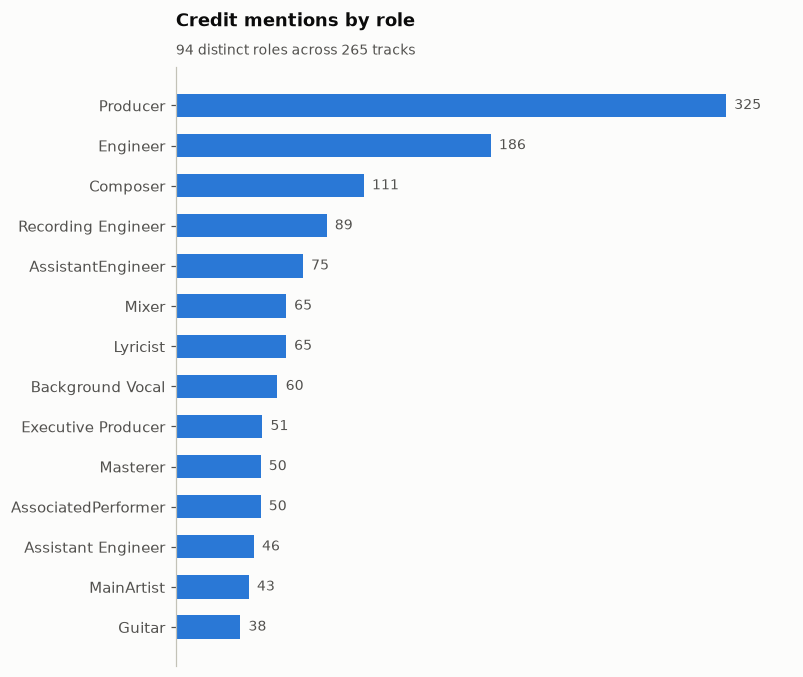

In [11]:
roles = collections.Counter()
for p in d['people']:
    for r, n in p['roles'].items():
        roles[r] += n
top = roles.most_common(14)
barh([r for r, _ in top], [n for _, n in top],
     'Credit mentions by role',
     f"{len(roles)} distinct roles across {seed['credited_tracks']} tracks")


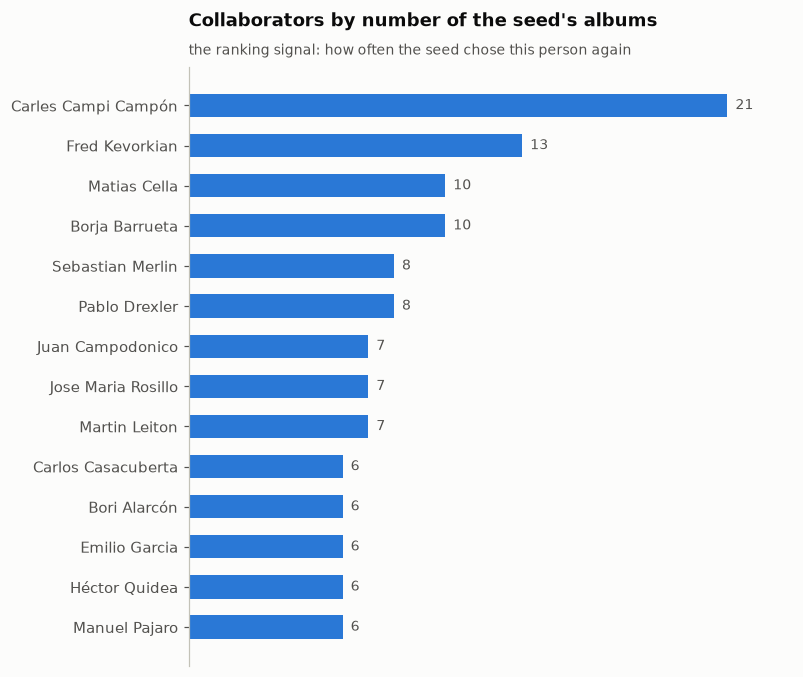

In [12]:
people = [p for p in d['people']][:14]
barh([p['names'][0][:26] for p in people],
     [p['stats']['albums'] for p in people],
     "Collaborators by number of the seed's albums",
     'the ranking signal: how often the seed chose this person again')


## 3. Resolution — names to artists, and a pool

`qobuz_resolve.py` takes those names, resolves each to a Qobuz artist id via the
storefront autosuggest, then fetches that artist's own releases to build a pool
of candidates to rank later.

This is the **lossy** half, kept separate so it can be re-run or hand-corrected
without re-crawling any albums.


In [13]:
w = load('watchlist.json'); pool = load('pool.json')
assert w and pool, 'run ./stages/resolve_qobuz.py first'
print(f"resolved   : {len(w['artists'])}")
print(f"unresolved : {len(w['unresolved'])}")
print(f"pool       : {pool['releases']:,} releases from {pool['artists_fetched']} artists")
conf = collections.Counter(a['resolved']['confidence'] for a in w['artists'])
print(f"confidence : {dict(conf)}")


resolved   : 68
unresolved : 54
pool       : 1,840 releases from 68 artists
confidence : {'exact': 68}


### Resolution fails on the people who matter most

Qobuz indexes *performers*, not studio staff — so the top collaborator and the
mastering engineer have no artist page at all. Section 4 recovers them via
Discogs; nothing in the Qobuz-only path can.

`pick()` refuses any non-exact name match on purpose: a wrong artist injects
dozens of bogus releases into the pool and is nearly impossible to notice later.
Every resolution below is `exact`; the failures are kept with their candidates
so they can be corrected by hand.


In [14]:
reasons = collections.Counter(u['reason'] for u in w['unresolved'])
print('why they failed:', dict(reasons), '\n')
for u in sorted(w['unresolved'], key=lambda u: -u['albums'])[:8]:
    cands = ', '.join(c['name'] for c in u['candidates'][:2]) or '-'
    print(f"  {u['albums']:>2} alb  {u['names'][0][:26]:<26} {u['reason']:<15} "
          f"candidates: {cands[:40]}")


why they failed: {'not_found': 29, 'no_exact_match': 25} 

  21 alb  Carles Campi Campón        not_found       candidates: -
  13 alb  Fred Kevorkian             not_found       candidates: -
  10 alb  Matias Cella               no_exact_match  candidates: Matías Collarte, Ivan Matias Calla
   7 alb  Jose Maria Rosillo         not_found       candidates: -
   6 alb  Bori Alarcón               not_found       candidates: -
   6 alb  Héctor Quidea              not_found       candidates: -
   6 alb  Manuel Pajaro              no_exact_match  candidates: Johan Manuel Pajaro, Francisco Manuel Pa
   6 alb  Néstor Cifuentes           not_found       candidates: -


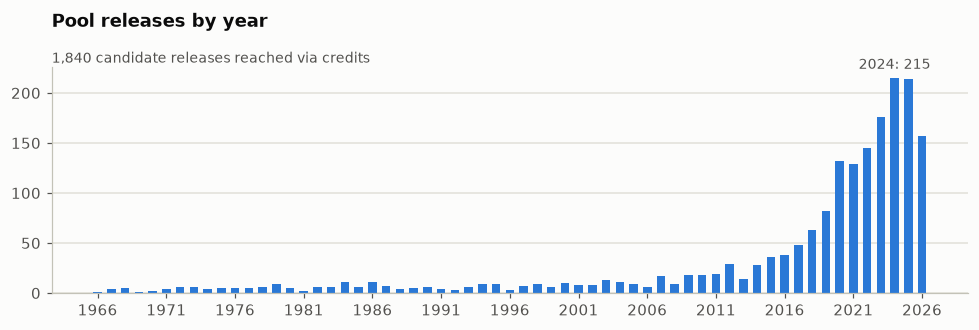

In [15]:
years = collections.Counter(r['date'][:4] for r in pool['pool'] if r['date'][:4].isdigit())
span = [str(y) for y in range(min(int(y) for y in years), max(int(y) for y in years) + 1)]
counts = [years.get(y, 0) for y in span]

fig, ax = plt.subplots(figsize=(9, 3.1))
ax.bar(span, counts, width=0.62, color=SERIES)          # thin marks
ax.set_axisbelow(True)                                   # recessive grid, behind data
ax.yaxis.grid(True, color=GRID, linewidth=1)
ax.xaxis.grid(False)
for s in ('top', 'right'):
    ax.spines[s].set_visible(False)
ax.set_xticks(span[::5]); ax.tick_params(axis='x', rotation=0)
# Selective label: annotate the peak only, never every bar.
peak = max(range(len(counts)), key=lambda i: counts[i])
ax.annotate(f'{span[peak]}: {counts[peak]}', (peak, counts[peak]),
            textcoords='offset points', xytext=(0, 6), ha='center',
            fontsize=9, color=INK2)
ax.set_title('Pool releases by year\n', loc='left')
ax.text(0, 1.02, f"{pool['releases']:,} candidate releases reached via credits",
        transform=ax.transAxes, fontsize=9, color=INK2)
fig.tight_layout(); plt.show()


### The pool is roughly half covers

Every pool row records *why* it is a candidate, in `via`. Grouping by the
referring role shows `Composer` referring nearly as many releases as `Producer`
— songwriters the seed covered, not people he worked with.

Discovery stays deliberately dumb about this; filtering belongs at ranking time.


In [16]:
via = collections.Counter(r['via']['top_role'] for r in pool['pool'])
for role, n in via.most_common(8):
    print(f'  {role:<18} {n:>5}')

print('\nnewest in the pool:')
for r in pool['pool'][:8]:
    who = ', '.join(r['artists'])[:34]
    print(f"  {r['date']}  {who:<34} {str(r['title'])[:28]:<28} "
          f"via {r['via']['name'][:18]} ({r['via']['top_role']})")


  Producer             463
  Composer             425
  Vocals               170
  MainArtist           165
  FeaturedArtist       117
  Conductor             79
  AssociatedPerformer    74
  Background Vocal      69

newest in the pool:
  2026-09-13  Mauro, David Hughes                Tão Bem (feat. David Hughes) via Mauro (Producer)
  2026-09-10  Baile Entero, Pablo Martin Jones   Sorteao                      via Pablo Martin Jones (Engineer)
  2026-08-30  Sabina                             Du bist mein Zuhause         via Sabina (Vocals)
  2026-08-28  PJ Sin Suela, Duo Deleite, Gyanma, Bubbaloo                     via PJ Sin Suela (MainArtist)
  2026-08-28  Bossa Viva, Leo Minax              Dunas                        via Leo Minax (Composer)
  2026-08-27  Sabina, Los Brasileros             Química                      via Sabina (Vocals)
  2026-08-27  Sabina                             MEDIANOCHE                   via Sabina (Vocals)
  2026-08-27  Sabina                          

## 4. Discogs — recovering the people Qobuz cannot see

Qobuz has **no reverse index**: a producer's own artist id does not list the
records they produced. Discogs has entities for everyone *and* that index.

`discogs_resolve.py` uses it as an index only — never mapping release to
release, which would be a second lossy join. It asks which **artists** a person
worked with, then matches those artists in Qobuz, which is reliable because
billed artists do have Qobuz pages.

```
unresolved name -> Discogs artist -> credits -> the ARTISTS on them
                                                     |
                           Qobuz autosuggest (exact) -+-> releases -> pool
```

Needs no token. Rate limited to 25 req/min (60 with `DISCOGS_TOKEN`), which is
what makes this the slow step.


In [ ]:
dw = load('discogs_watchlist.json'); dpool = load('pool_discogs.json')
if not dw:
    print('run ./stages/resolve_discogs.py --top 12 first')
else:
    print(f"recovered        : {len(dw['recovered'])}")
    print(f"still unresolved : {len(dw['still_unresolved'])} "
          f"{[u['names'][0] for u in dw['still_unresolved']]}")
    print(f"artists they worked with: {len(dw['collaborator_candidates'])}\n")
    print(f"{'seed':>4} {'credits':>8}  {'name':<26} roles")
    for e in dw['recovered'][:10]:
        print(f"{e['seed_albums']:>4} {e['credited_releases']:>8}  "
              f"{e['names'][0][:26]:<26} {list(e['roles'])[:3]}")


### What a recovered person unlocks

`Carles Campi Campón` produced 21 of the seed's albums and has no Qobuz artist
page. Discogs shows who else he produced — and those artists *are* on Qobuz.


In [ ]:
if dw:
    for e in dw['recovered'][:3]:
        print(f"=== {e['names'][0]} ({e['seed_albums']} seed albums) ===")
        for w in e['worked_with'][:6]:
            print(f"    {w['releases']}x  {w['name'][:32]:<32} {w['roles']}")
        print()


### The overlap is the whole argument

If the Discogs path mostly rediscovered what the Qobuz path already had, it
would not be worth the rate limit. It does not.


In [ ]:
if dw and dpool:
    qids = {r['album_id'] for r in pool['pool']}
    dids = {r['album_id'] for r in dpool['pool']}
    print(f"qobuz-path pool      : {len(qids):>6,}")
    print(f"discogs-path pool    : {len(dids):>6,}")
    print(f"overlap              : {len(qids & dids):>6,}")
    print(f"NEW only via discogs : {len(dids - qids):>6,}")
    print(f"\ncollaborators Qobuz could not match: {len(dpool['qobuz_unmatched'])}")
    print('\nnewest, showing the studio person each came through:')
    for r in dpool['pool'][:8]:
        who = ', '.join(r['artists'])[:24]
        through = ', '.join(r['via']['through'])[:22]
        print(f"  {r['date']}  {who:<24} {str(r['title'])[:24]:<24} "
              f"via {r['via']['name'][:16]:<16} <- {through}")


In [ ]:
if dw and dw['collaborator_candidates']:
    top = dw['collaborator_candidates'][:14]
    barh([c['name'][:26] for c in top],
         [c['releases'] for c in top],
         'Artists reached through a studio person',
         'releases made together, per Discogs credits')


### Not a free lunch

- **Rate limit dominates**: ~5 minutes for 12 people anonymously; all 54 would
  be ~20 minutes.
- **Average relevance is lower.** This pool is 3.5x bigger than the Qobuz one,
  but *We Are Scientists* via a mixing engineer is a thin thread. Ranking
  should weight `via.path` and `seed_albums`.
- **Discogs is not a discovery source.** It has no record of the seed's
  2026-08-06 single — the same staleness that makes ListenBrainz miss it — and
  lists 48 of his releases against Qobuz's 63. Use it as an index, not a
  catalogue.


## Limits

- **Qobuz resolution loses 54 of 122 names**, producers and engineers worst.
  `discogs_resolve.py` recovers them, but only as far as `--top` reaches.
- **Name variants are not deduped before the Discogs lookup**, so `Carles
  Campón` is searched separately from `Carles Campi Campón` and fails, on a
  person already recovered.
- **Half the Qobuz pool is cover sources**, not collaborators. Use
  `via.classes` / `cover_source_only`, or `--no-cover-sources`.
- **No ranking yet.** Both pools are unranked candidates; weighting a 7-album
  producer above a 2-album composer is the next design step.
- **One seed at a time.** Multiple seeds reintroduce name collisions a single
  seed does not have (two `Mauro`s, two `Javier Colina`s).
- **Four unrelated id namespaces** (MusicBrainz, Apple, Qobuz, Discogs). Keep
  them side by side; never join them.
- **Qobuz omits `release_type`**, so Album/EP/Single is inferred from track
  count — a 6-track album is labelled EP.
- **Static PNGs**, so these charts have no hover layer. The tables beside each
  chart are the accessible view of the same numbers.
